In [3]:
library(class)  # For KNN classification
library(caret)  # For train-test split
library(ggplot2)  # For visualization
library(plotly)
library(dplyr)

In [5]:
# Load dataset
diabetes <- read.csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv", header = FALSE)

# Assign column names
colnames(diabetes) <- c("Pregnancies", "Glucose", "BP", "SkinThickness", "Insulin", "BMI", "DiabetesPedigree", "Age", "Outcome")

# Convert Outcome to factor (0 = No Diabetes, 1 = Diabetes)
diabetes$Outcome <- as.factor(diabetes$Outcome)

# Define normalization function
normalize <- function(x) {
  return((x - min(x)) / (max(x) - min(x)))
}

# Normalize numeric features only
diabetes_norm <- as.data.frame(lapply(diabetes[, -ncol(diabetes)], normalize))
diabetes_norm$Outcome <- diabetes$Outcome  # Add back target column


Accuracy for K = 1: 70.13%
Accuracy for K = 2: 74.68%
Accuracy for K = 3: 75.97%
Accuracy for K = 4: 72.73%
Accuracy for K = 5: 75.32%
[1] "Confusion Matrix for Best K:"
         Actual
Predicted  0  1
        0 89 24
        1 13 28


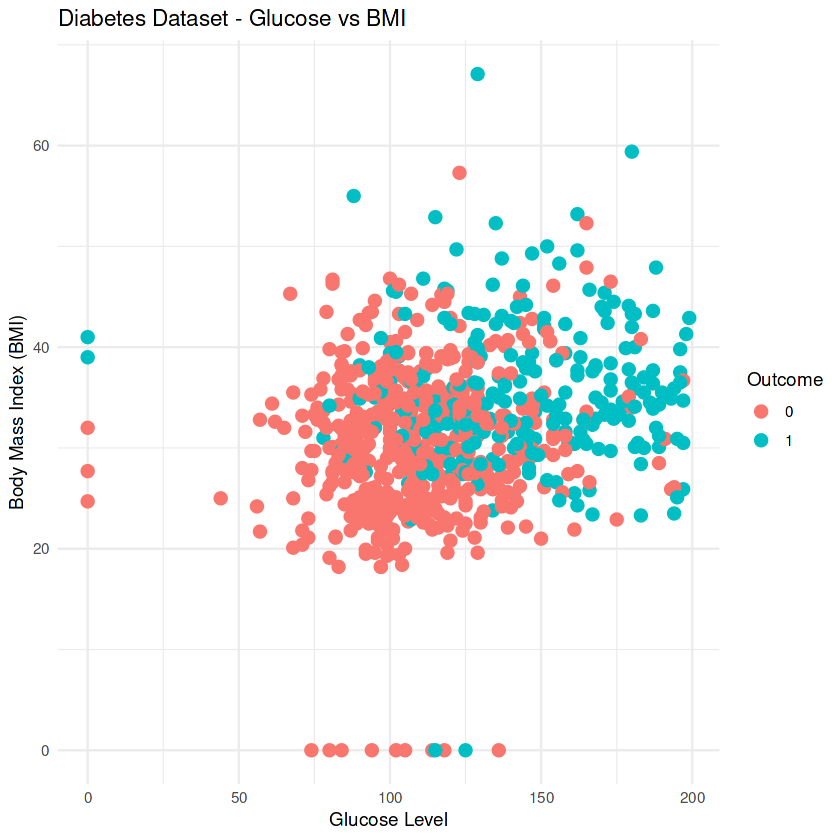

In [7]:

# Train-test split (80-20)
set.seed(123)
train_index <- sample(seq_len(nrow(diabetes_norm)), size = 0.8 * nrow(diabetes_norm))
train_features <- diabetes_norm[train_index, -ncol(diabetes_norm)]
test_features <- diabetes_norm[-train_index, -ncol(diabetes_norm)]
train_target <- diabetes_norm$Outcome[train_index]
test_target <- diabetes_norm$Outcome[-train_index]

# Function to evaluate KNN
evaluate_knn <- function(k_value) {
  predicted <- knn(train = train_features, test = test_features, cl = train_target, k = k_value)
  accuracy <- mean(predicted == test_target) * 100
  cat(sprintf("Accuracy for K = %d: %.2f%%\n", k_value, accuracy))
}

# Test accuracy for K = 1 to 5
for (k in 1:5) {
  evaluate_knn(k)
}

# Confusion matrix for best K
best_k <- 3
predicted_best <- knn(train = train_features, test = test_features, cl = train_target, k = best_k)
conf_matrix <- table(Predicted = predicted_best, Actual = test_target)
print("Confusion Matrix for Best K:")
print(conf_matrix)

# Scatter plot: Glucose vs BMI
ggplot(diabetes, aes(x = Glucose, y = BMI, color = Outcome)) +
  geom_point(size = 3) +
  theme_minimal() +
  labs(title = "Diabetes Dataset - Glucose vs BMI",
       x = "Glucose Level",
       y = "Body Mass Index (BMI)")
